# ChurnGuard AI | Investigación reproducible y propuesta comercial
**Tarea 6 · Optimización de Machine Learning, Explainable AI y Business Pitch**  
**Ejecución:** Jupyter local, con `archive/WA_Fn-UseC_-Telco-Customer-Churn.csv` junto al notebook.  
**Ruta crítica:** imports → EDA → diseño experimental → benchmark → Grid/Random/TPE → genética → NSGA-II → selección y umbral → evaluación final → SHAP/LIME → negocio y exportación.

> **Integridad experimental:** todo ajuste se hace en entrenamiento con CV estratificada. El test se consulta una sola vez al finalizar la selección. Si el test de este mismo dataset ya se examinó en iteraciones anteriores, no es una prueba externa completamente nueva; se declara esta limitación. No se prometen niveles de Accuracy ni retornos financieros antes de medirlos.

**Interpretación de métricas** (renderizado MathJax de Jupyter):

$$\operatorname{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\qquad \operatorname{Recall}=\frac{TP}{TP+FN}$$

$$F_1=\frac{2\,\operatorname{Precision}\,\operatorname{Recall}}{\operatorname{Precision}+\operatorname{Recall}},\qquad \operatorname{RMSE}=\sqrt{\frac1n\sum_{i=1}^{n}(y_i-\hat y_i)^2}$$

**Nota:** RMSE se muestra para ejemplificar el correcto formato de raíz; no es la métrica principal de clasificación.

In [1]:
# PASO 1 · IMPORTACIONES Y CONFIGURACIÓN LOCAL
# Primera ejecución, si faltan dependencias:
# %pip install -U numpy pandas scikit-learn matplotlib seaborn plotly optuna catboost lightgbm xgboost shap lime joblib
from pathlib import Path
import os, time, json, warnings, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve,
                             brier_score_loss, classification_report)
from sklearn.calibration import calibration_curve
from scipy.stats import randint, loguniform, uniform
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import optuna
import shap
from lime.lime_tabular import LimeTabularExplainer
import plotly.express as px
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
np.random.seed(SEED)
ROOT=Path.cwd()
CSV=ROOT/'archive'/'WA_Fn-UseC_-Telco-Customer-Churn.csv'
ART=ROOT/'artifacts'; FIG=ART/'figures'; MODELS=ART/'models'; REPORTS=ART/'reports'
for p in (FIG,MODELS,REPORTS):p.mkdir(parents=True,exist_ok=True)
# Presupuesto rápido inicial; cambiar a 'deep' para experimentación profunda (puede tardar horas)
PROFILE='quick'  # 'quick' o 'deep'
BUDGET={'quick':dict(grid=12,random=12,tpe=12,ga_pop=6,ga_gen=3,nsga_pop=8,nsga_gen=3,folds=3),
        'deep':dict(grid=24,random=60,tpe=80,ga_pop=12,ga_gen=8,nsga_pop=16,nsga_gen=8,folds=5)}[PROFILE]
N_JOBS=2  # limitar hilos para comparar tiempos y no saturar el equipo
print('Python:',sys.version.split()[0],'| Sistema:',platform.platform(),'| Directorio:',ROOT)
print('Presupuesto:',PROFILE,BUDGET)
assert CSV.is_file(), f'No se encontró: {CSV}. Ejecuta Jupyter desde la raíz del proyecto.'

Python: 3.10.20 | Sistema: Linux-6.17.0-35-generic-x86_64-with-glibc2.39 | Directorio: /home/paul/Documents/SEMESTRE 8/PA - APRENDIZAJE AUTOMATICO /Repository/Optimización de Machine Learning, Explainable AI y Business Pitch
Presupuesto: quick {'grid': 12, 'random': 12, 'tpe': 12, 'ga_pop': 6, 'ga_gen': 3, 'nsga_pop': 8, 'nsga_gen': 3, 'folds': 3}


Dimensiones: (7043, 21) | Churn: 0.2654 | Duplicados IDs: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


,dtype,nulos,unicos
TotalCharges,float64,11,6530
customerID,object,0,7043
DeviceProtection,object,0,3
MonthlyCharges,float64,0,1585
PaymentMethod,object,0,4
PaperlessBilling,object,0,2
Contract,object,0,3
StreamingMovies,object,0,3
StreamingTV,object,0,3
TechSupport,object,0,3


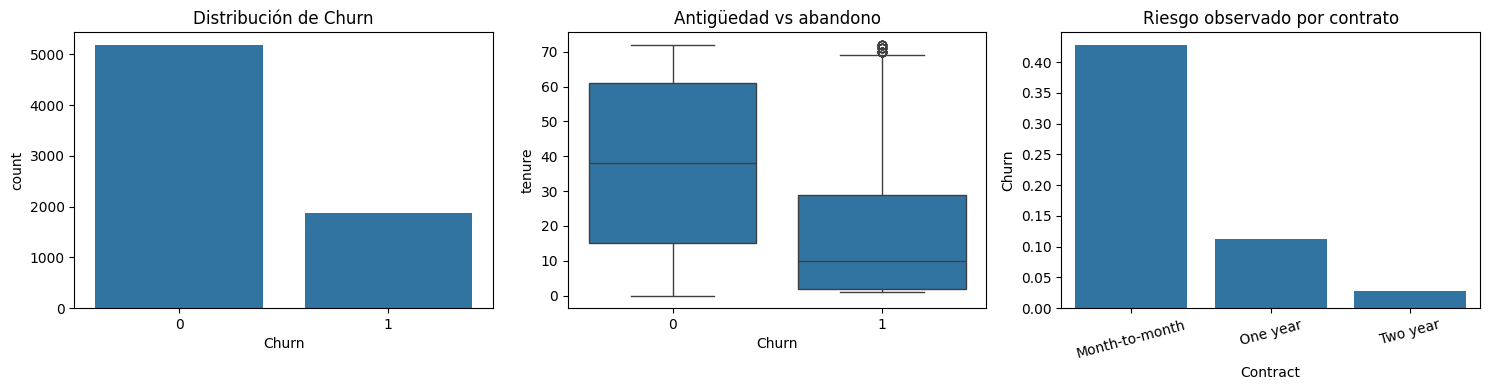

,Contract,clientes,tasa_churn,ingreso_mensual_promedio
0,Month-to-month,3875,0.427097,66.398490
1,One year,1473,0.112695,65.048608
2,Two year,1695,0.028319,60.770413


Dev/test: (5634, 19) (1409, 19) | Numéricas: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'] | Categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Balance train/test: 0.2654 0.2654


In [2]:
# PASO 2 · EDA, CALIDAD, SEGMENTOS, KPI Y DIVISIÓN ESTRATIFICADA
raw=pd.read_csv(CSV)
assert {'Churn','customerID','TotalCharges'}.issubset(raw.columns), 'CSV inesperado'
raw['TotalCharges']=pd.to_numeric(raw['TotalCharges'],errors='coerce')
assert set(raw['Churn'].dropna().unique()) <= {'Yes','No'}, 'Etiquetas inesperadas'
raw['Churn']=raw['Churn'].map({'No':0,'Yes':1}).astype(int)
print('Dimensiones:',raw.shape,'| Churn:',raw.Churn.mean().round(4),'| Duplicados IDs:',raw.customerID.duplicated().sum())
display(raw.head(3)); display(pd.DataFrame({'dtype':raw.dtypes.astype(str),'nulos':raw.isna().sum(),'unicos':raw.nunique()}).sort_values('nulos',ascending=False).head(21))
assert raw.customerID.is_unique, 'Revisar ID duplicados antes de continuar'
fig,ax=plt.subplots(1,3,figsize=(15,4))
sns.countplot(data=raw,x='Churn',ax=ax[0]); ax[0].set_title('Distribución de Churn')
sns.boxplot(data=raw,x='Churn',y='tenure',ax=ax[1]); ax[1].set_title('Antigüedad vs abandono')
sns.barplot(data=raw,x='Contract',y='Churn',ax=ax[2],errorbar=None); ax[2].set_title('Riesgo observado por contrato');ax[2].tick_params(axis='x',rotation=15)
plt.tight_layout();plt.savefig(FIG/'eda.png',dpi=145);plt.show()
eda_summary=raw.groupby('Contract',observed=True).agg(clientes=('Churn','size'),tasa_churn=('Churn','mean'),ingreso_mensual_promedio=('MonthlyCharges','mean')).reset_index()
display(eda_summary)
# customerID solo es identificador; no predictor. No aplicamos imputación antes del split.
X=raw.drop(columns=['Churn','customerID']).copy();y=raw['Churn'].copy()
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
num_cols=X_dev.select_dtypes(include=np.number).columns.tolist()
cat_cols=X_dev.select_dtypes(exclude=np.number).columns.tolist()
print('Dev/test:',X_dev.shape,X_test.shape,'| Numéricas:',num_cols,'| Categóricas:',cat_cols)
print('Balance train/test:',round(y_dev.mean(),4),round(y_test.mean(),4))

## PASO 3 · Diseño del benchmark y configuraciones

Los seis enfoques se comparan sobre **las mismas particiones estratificadas** y sin mirar el test. Los modelos basados en árboles usan One-Hot para mantener una interfaz homogénea para las explicaciones; CatBoost puede procesar categorías nativamente, pero aquí se adopta codificación común para comparación controlada.

| Modelo | Configuración inicial | Hiperparámetros relevantes | Explicabilidad |
|:--|:--|:--|:--|
| Regresión logística | `C=1`, `max_iter=2000` | `C`, `class_weight` | Coeficientes, SHAP, LIME |
| Random Forest | `n_estimators=400`, `max_depth=10`, `min_samples_leaf=4` | árboles, profundidad, hoja | Importancia, SHAP, LIME |
| CatBoost | `iterations=500`, `depth=5`, `learning_rate=.04` | iteraciones, profundidad, L2 | TreeSHAP, LIME |
| LightGBM | `n_estimators=500`, `num_leaves=15`, `learning_rate=.04` | hojas, profundidad, regularización | TreeSHAP, LIME |
| XGBoost | `n_estimators=500`, `max_depth=4`, `learning_rate=.04` | árboles, profundidad, muestreo | TreeSHAP, LIME |
| Stacking | LR + CatBoost + LightGBM; meta LR | composición, meta estimador | Explicación por modelo-agnóstico |

**Selección primaria:** ROC-AUC en CV; **secundarias:** F1, Accuracy, Recall, Brier y dispersión. No se selecciona usando el test.  
**Nota sobre presupuestos:** `quick` da una revisión inicial; cambia `PROFILE='deep'` en el Paso 1 y ejecuta de nuevo antes de presentar una comparación definitiva. Los métodos evolutivos y NSGA-II se ejecutan sobre el **mismo CatBoost** empleado en Grid/Random/TPE.

In [3]:
# PASO 4 · PIPELINES, BASELINES Y BENCHMARK
try: encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError: encoder=OneHotEncoder(handle_unknown='ignore',sparse=False)
prep=ColumnTransformer([
    ('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),
    ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('onehot',encoder)]),cat_cols)
],verbose_feature_names_out=True)

def pipe(model):return Pipeline([('prep',prep),('model',model)])

def cb(**kw):return CatBoostClassifier(iterations=500,depth=5,learning_rate=.04,l2_leaf_reg=3,
                                      loss_function='Logloss',verbose=False,thread_count=N_JOBS,
                                      random_seed=SEED,allow_writing_files=False,**kw)
models={
 'LogisticRegression':pipe(LogisticRegression(C=1,max_iter=2000,random_state=SEED)),
 'RandomForest':pipe(RandomForestClassifier(n_estimators=400,max_depth=10,min_samples_leaf=4,n_jobs=N_JOBS,random_state=SEED)),
 'CatBoost':pipe(cb()),
 'LightGBM':pipe(LGBMClassifier(n_estimators=500,num_leaves=15,learning_rate=.04,min_child_samples=30,
                                verbosity=-1,n_jobs=N_JOBS,random_state=SEED)),
 'XGBoost':pipe(XGBClassifier(n_estimators=500,max_depth=4,learning_rate=.04,subsample=.8,
                              colsample_bytree=.8,n_jobs=N_JOBS,random_state=SEED,eval_metric='logloss')),
}
models['Stacking']=Pipeline([('prep',prep),('model',StackingClassifier(estimators=[
    ('lr',LogisticRegression(max_iter=1500)),('cb',CatBoostClassifier(iterations=300,depth=5,learning_rate=.04,verbose=False,thread_count=N_JOBS,random_seed=SEED,allow_writing_files=False)),
    ('lgb',LGBMClassifier(n_estimators=300,num_leaves=15,verbosity=-1,n_jobs=N_JOBS,random_state=SEED))],
    final_estimator=LogisticRegression(max_iter=1200),cv=3,n_jobs=1))])
cv=StratifiedKFold(n_splits=BUDGET['folds'],shuffle=True,random_state=SEED)
scoring={'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'}
benchmark=[]
for name,est in models.items():
    t=time.perf_counter();res=cross_validate(est,X_dev,y_dev,cv=cv,scoring=scoring,n_jobs=1,error_score='raise')
    benchmark.append({'modelo':name,**{k:np.mean(res['test_'+k]) for k in scoring},
                      'roc_auc_std':np.std(res['test_roc_auc']), 'segundos':time.perf_counter()-t})
bench=pd.DataFrame(benchmark).sort_values('roc_auc',ascending=False).reset_index(drop=True)
display(bench.style.format({c:'{:.4f}' for c in scoring}).format({'roc_auc_std':'{:.4f}','segundos':'{:.1f}'}))
bench.to_csv(REPORTS/'baseline_cv.csv',index=False)
fig=px.bar(bench,x='modelo',y='roc_auc',error_y='roc_auc_std',title='Benchmark ROC-AUC: solo desarrollo');fig.show()

,modelo,accuracy,precision,recall,f1,roc_auc,roc_auc_std,segundos
0,Stacking,0.807774,0.679068,0.523748,0.591176,0.848887,0.0074,12.2
1,LogisticRegression,0.803159,0.655442,0.545141,0.595173,0.845795,0.0076,1.5
2,RandomForest,0.800142,0.665077,0.499675,0.570080,0.845305,0.0079,6.3
3,CatBoost,0.797835,0.651783,0.514396,0.574149,0.843456,0.0068,3.5
4,XGBoost,0.796060,0.643491,0.520412,0.574776,0.838004,0.0076,1.5
5,LightGBM,0.795705,0.640979,0.524418,0.576320,0.833662,0.0084,1.5


## PASO 5 · Optimización monoobjetivo: mismo CatBoost, misma CV

**Espacios:** árboles 200–1000, profundidad 3–8, learning rate 0,01–0,15 y penalización L2 1–10. Grid utiliza una rejilla declarada; Random y TPE usan dominios equivalentes. Todos se puntúan mediante **ROC-AUC de CV**. Las configuraciones y tiempos se guardan por separado.  

$$\theta^*=\arg\max_{\theta\in\Theta}\frac{1}{K}\sum_{k=1}^{K}\operatorname{AUC}\left(f_{\theta}^{(-k)},D_k\right)$$

El estimador se ajusta dentro de cada fold, con el preprocesamiento dentro del pipeline.

,metodo,modelo,roc_auc_cv,segundos,configuraciones,hiperparametros
0,Grid,CatBoost,0.850029,46.65,12,"{""model__depth"": 4, ""model__iterations"": 300, ..."
2,TPE,CatBoost,0.849265,63.90,12,"{""model__iterations"": 700, ""model__depth"": 3, ..."
1,Random,CatBoost,0.848304,62.51,12,"{""model__depth"": 5, ""model__iterations"": 258, ..."


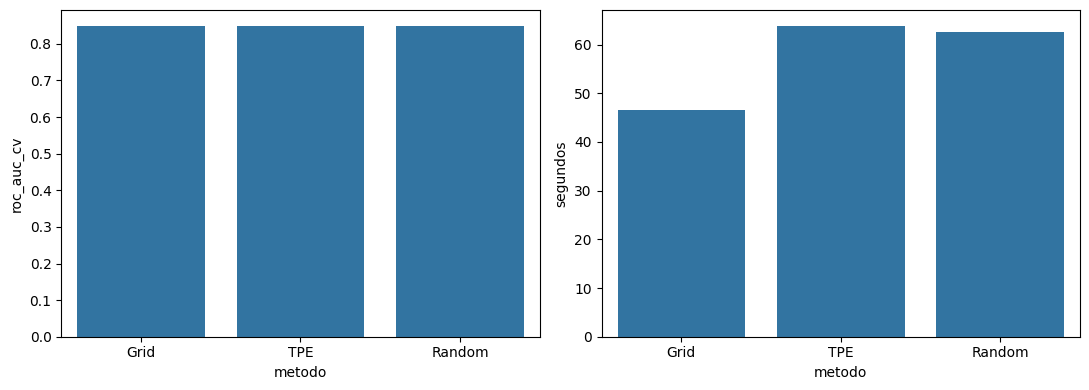

In [4]:
# PASO 6 · GRID, RANDOM, TPE: REGISTRO DE TIEMPOS Y CONFIGURACIONES
base_cb=models['CatBoost'];opt_rows=[];candidate_configs=[]
def report_opt(name,best_params,best_score,seconds,n_evals):
    opt_rows.append({'metodo':name,'modelo':'CatBoost','roc_auc_cv':float(best_score),'segundos':round(seconds,2),
                     'configuraciones':int(n_evals),'hiperparametros':json.dumps(best_params)})
    candidate_configs.append((name,dict(best_params),float(best_score)))

# Rejilla explícita: 12 configuraciones en quick y 24 en deep.
grid_space={'model__iterations':[300,600,900], 'model__depth':[4,6],
            'model__learning_rate':([.03,.08] if PROFILE=='quick' else [.02,.04,.08,.12]), 'model__l2_leaf_reg':[3]}
t=time.perf_counter()
grid=GridSearchCV(base_cb,grid_space,cv=cv,scoring='roc_auc',n_jobs=1,refit=False,error_score='raise')
grid.fit(X_dev,y_dev)
report_opt('Grid',grid.best_params_,grid.best_score_,time.perf_counter()-t,len(grid.cv_results_['params']))

random_space={'model__iterations':randint(200,1001),'model__depth':randint(3,9),
              'model__learning_rate':loguniform(.01,.15),'model__l2_leaf_reg':uniform(1,9)}
t=time.perf_counter()
rnd=RandomizedSearchCV(base_cb,random_space,n_iter=BUDGET['random'],cv=cv,scoring='roc_auc',
                       random_state=SEED,n_jobs=1,refit=False,error_score='raise')
rnd.fit(X_dev,y_dev)
report_opt('Random',rnd.best_params_,rnd.best_score_,time.perf_counter()-t,len(rnd.cv_results_['params']))

def cv_auc(params):
    est=pipe(CatBoostClassifier(loss_function='Logloss',verbose=False,thread_count=N_JOBS,
                                random_seed=SEED,allow_writing_files=False,**params))
    return float(cross_validate(est,X_dev,y_dev,cv=cv,scoring='roc_auc',n_jobs=1)['test_score'].mean())

def suggest(trial):
    return {'iterations':trial.suggest_int('iterations',200,1000,step=50),
            'depth':trial.suggest_int('depth',3,8),
            'learning_rate':trial.suggest_float('learning_rate',.01,.15,log=True),
            'l2_leaf_reg':trial.suggest_float('l2_leaf_reg',1,10)}
optuna.logging.set_verbosity(optuna.logging.WARNING)
t=time.perf_counter()
tpe=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
tpe.optimize(lambda trial:cv_auc(suggest(trial)),n_trials=BUDGET['tpe'],show_progress_bar=False)
report_opt('TPE',{'model__'+k:v for k,v in tpe.best_params.items()},tpe.best_value,time.perf_counter()-t,len(tpe.trials))
opt_table=pd.DataFrame(opt_rows).sort_values('roc_auc_cv',ascending=False)
display(opt_table)
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.barplot(opt_table,x='metodo',y='roc_auc_cv',ax=ax[0]);sns.barplot(opt_table,x='metodo',y='segundos',ax=ax[1]);plt.tight_layout();plt.show()

## PASO 7 · Algoritmo genético (GA)
Un cromosoma codifica `[n_estimators, depth, learning_rate, L2]`; evaluación = ROC-AUC de CV. Torneo, cruzamiento uniforme, mutación con límites y elitismo. La bitácora muestra la evolución del **fitness**. Se compara con los demás optimizadores sobre **CatBoost**.

$$\operatorname{fitness}(\theta)=\overline{\operatorname{ROC\mbox{-}AUC}}_{CV}(\theta)$$

,generacion,mejor_auc,media_auc,evaluaciones_unicas
0,1,0.847771,0.835961,6
1,2,0.848656,0.847874,9
2,3,0.848777,0.848320,13


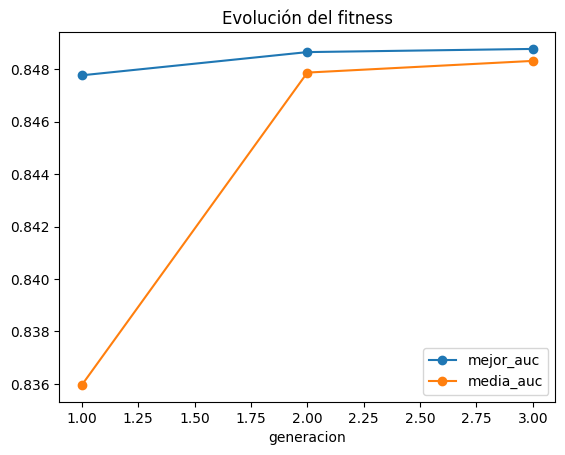

In [5]:
# PASO 8 · GA REPRODUCIBLE (SIN LEAKAGE)
rng=np.random.default_rng(SEED)
def clip_gene(g):
    return [int(np.clip(round(g[0]/50)*50,200,1000)),int(np.clip(round(g[1]),3,8)),
            float(np.clip(g[2],.01,.15)),float(np.clip(g[3],1,10))]
def rand_gene():return [int(rng.integers(4,21))*50,int(rng.integers(3,9)),float(np.exp(rng.uniform(np.log(.01),np.log(.15)))),float(rng.uniform(1,10))]
def gene_params(g):return dict(iterations=g[0],depth=g[1],learning_rate=g[2],l2_leaf_reg=g[3])
fitness_cache={}
def gene_score(g):
    key=(g[0],g[1],round(g[2],8),round(g[3],7))
    if key not in fitness_cache:fitness_cache[key]=cv_auc(gene_params(g))
    return fitness_cache[key]
def tournament(p,s,k=3):
    ii=rng.choice(len(p),size=min(k,len(p)),replace=False)
    return p[max(ii,key=lambda i:s[i])].copy()
def crossover(a,b):return [a[i] if rng.random()<.5 else b[i] for i in range(4)]
def mutate(g,p=.20):
    g=g.copy()
    if rng.random()<p:g[0]+=int(rng.choice([-200,-100,100,200]))
    if rng.random()<p:g[1]+=int(rng.choice([-2,-1,1,2]))
    if rng.random()<p:g[2]*=float(np.exp(rng.normal(0,.3)))
    if rng.random()<p:g[3]+=float(rng.normal(0,1.5))
    return clip_gene(g)
t=time.perf_counter();population=[rand_gene() for _ in range(BUDGET['ga_pop'])];hist=[]
for gen in range(BUDGET['ga_gen']):
    scores=[gene_score(g) for g in population]
    hist.append({'generacion':gen+1,'mejor_auc':max(scores),'media_auc':np.mean(scores),'evaluaciones_unicas':len(fitness_cache)})
    elite=population[int(np.argmax(scores))].copy()
    new=[elite]
    while len(new)<len(population):
        a=tournament(population,scores);b=tournament(population,scores)
        child=crossover(a,b) if rng.random()<.8 else a
        new.append(mutate(child))
    population=new
scores=[gene_score(g) for g in population]
idx=int(np.argmax(scores));ga_gene=population[idx]
ga_params={'model__'+k:v for k,v in gene_params(ga_gene).items()}
report_opt('GA',ga_params,scores[idx],time.perf_counter()-t,len(fitness_cache))
ga_history=pd.DataFrame(hist);display(ga_history)
ga_history.plot(x='generacion',y=['mejor_auc','media_auc'],marker='o',title='Evolución del fitness');plt.show()

## PASO 9 · NSGA-II: dos objetivos y frente de Pareto

$$\max\,F_1(\theta),\qquad \min\,T_{\mathrm{inferencia}}(\theta)$$

La latencia se mide sobre el mismo subconjunto de desarrollo, después de ajustar el pipeline en cada fold. El algoritmo usa **NSGA-II** (selección por rangos no dominados y *crowding distance*) a través de Optuna; sus operadores de cruce/mutación evolucionan configuraciones. Los tiempos de entrenamiento son distintos de los de inferencia y se reportan por separado. El frente debe verificarse antes de recomendar un compromiso.

In [6]:
# PASO 10 · OPTIMIZACIÓN MULTIOBJETIVO (NSGA-II)
# CV para F1; se mide latencia de predict_proba por cliente con el modelo del último fold.
from sklearn.base import clone
from sklearn.metrics import f1_score
splits=list(cv.split(X_dev,y_dev)); eval_batch=X_dev.iloc[:min(256,len(X_dev))]
def multi_eval(params):
    f1s=[]; lat=[]
    for tr,va in splits:
        e=pipe(CatBoostClassifier(loss_function='Logloss',verbose=False,thread_count=N_JOBS,
                                  random_seed=SEED,allow_writing_files=False,**params))
        e.fit(X_dev.iloc[tr],y_dev.iloc[tr]); pv=e.predict(X_dev.iloc[va]);f1s.append(f1_score(y_dev.iloc[va],pv))
        # calentamiento; medición por lote y por cliente en ms
        e.predict_proba(eval_batch)
        tic=time.perf_counter()
        for _ in range(3):e.predict_proba(eval_batch)
        lat.append((time.perf_counter()-tic)*1000/(3*len(eval_batch)))
    return float(np.mean(f1s)),float(np.median(lat))
t=time.perf_counter()
nsga=optuna.create_study(directions=['maximize','minimize'],sampler=optuna.samplers.NSGAIISampler(seed=SEED,
                        population_size=BUDGET['nsga_pop'],crossover_prob=.8,mutation_prob=.2))
nsga.optimize(lambda trial:multi_eval(suggest(trial)),n_trials=BUDGET['nsga_pop']*BUDGET['nsga_gen'],show_progress_bar=False)
nsga_seconds=time.perf_counter()-t
pareto=pd.DataFrame([{'trial':v.number,'f1_cv':v.values[0],'ms_cliente':v.values[1],**v.params} for v in nsga.best_trials])
all_nsga=pd.DataFrame([{'trial':v.number,'f1_cv':v.values[0],'ms_cliente':v.values[1]} for v in nsga.trials if v.values is not None])
display(pareto.sort_values('f1_cv',ascending=False))
fig=px.scatter(all_nsga,x='ms_cliente',y='f1_cv',hover_data=['trial'],title='NSGA-II: todas las soluciones; Pareto destacado')
fig.add_scatter(x=pareto.ms_cliente,y=pareto.f1_cv,mode='markers',name='Pareto',marker={'size':13,'symbol':'diamond'})
fig.show()
# Política empresarial DECLARADA: elegir el mayor F1 dentro del percentil 50 de latencia Pareto;
# el criterio se define antes de consultar el conjunto de prueba.
lat_limit=float(pareto.ms_cliente.median()); feasible=pareto[pareto.ms_cliente<=lat_limit]
selected_pareto=feasible.sort_values('f1_cv',ascending=False).iloc[0]
print('NSGA-II:',len(nsga.trials),'evaluaciones | segundos:',round(nsga_seconds,1),'| criterio latencia <=',round(lat_limit,4),'ms/cliente')
print('Punto de Pareto elegido:',selected_pareto.to_dict())

,trial,f1_cv,ms_cliente,iterations,depth,learning_rate,l2_leaf_reg
2,19,0.584739,0.038167,450,5,0.017173,3.621062
3,22,0.583065,0.037297,700,5,0.020153,4.297257
1,18,0.579477,0.036343,700,7,0.010573,5.628110
0,4,0.572902,0.035422,450,6,0.032211,3.621062


NSGA-II: 24 evaluaciones | segundos: 114.9 | criterio latencia <= 0.0368 ms/cliente
Punto de Pareto elegido: {'trial': 18.0, 'f1_cv': 0.5794773643633633, 'ms_cliente': 0.03634317057314244, 'iterations': 700.0, 'depth': 7.0, 'learning_rate': 0.010573268083515799, 'l2_leaf_reg': 5.628109945722504}


## PASO 11 · Elección final, ajuste del umbral y evaluación independiente

Se elige el modelo por **ROC-AUC de CV**, entre el mejor baseline y las configuraciones optimizadas de CatBoost. NSGA-II se informa como **solución alternativa comercial**; no se mezcla su F1 con ROC-AUC para seleccionar. Una vez elegido el modelo, las probabilidades *out-of-fold* sobre desarrollo permiten seleccionar el umbral por F1 (podemos usar posteriormente una función de beneficio/costo). La tabla de prueba se calcula **una sola vez** al final.

,metodo,roc_auc_cv,segundos,configuraciones
0,Grid,0.850029,46.65,12
1,TPE,0.849265,63.90,12
2,GA,0.849002,64.43,15
3,Random,0.848304,62.51,12


Seleccionado: CatBoost | método: Grid | ROC-AUC CV: 0.85
Umbral elegido por F1 OOF: 0.35


,modelo,selector,umbral,accuracy,precision,recall,f1,roc_auc,brier
0,CatBoost,Grid,0.35,0.778566,0.565126,0.719251,0.632941,0.846196,0.135006


              precision    recall  f1-score   support

 Se mantiene       0.89      0.80      0.84      1035
    Abandona       0.57      0.72      0.63       374

    accuracy                           0.78      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.80      0.78      0.79      1409



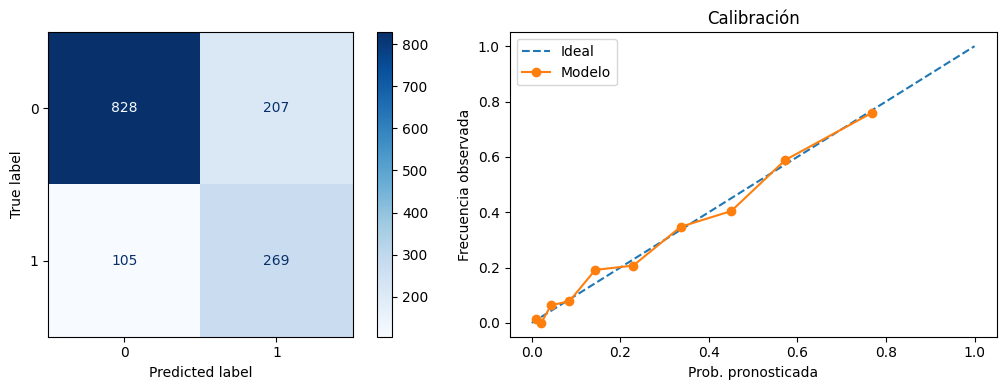

In [7]:
# PASO 12 · SELECCIÓN SIN VER TEST, UMBRAL OOF Y EVALUACIÓN FINAL
# El GA ya está integrado; Grid, Random, TPE y GA se comparan a igual CV.
opt_table=pd.DataFrame(opt_rows).sort_values('roc_auc_cv',ascending=False).reset_index(drop=True)
display(opt_table[['metodo','roc_auc_cv','segundos','configuraciones']])
cv_winner=opt_table.iloc[0]; baseline_winner=bench.iloc[0]
if baseline_winner.roc_auc >= cv_winner.roc_auc_cv:
    selected_name=str(baseline_winner.modelo)
    best_est=models[selected_name]
    selected_cv_auc=float(baseline_winner.roc_auc)
    selection_type='Baseline CV'
else:
    selected_name='CatBoost'
    best_est=base_cb.set_params(**json.loads(cv_winner.hiperparametros))
    selected_cv_auc=float(cv_winner.roc_auc_cv)
    selection_type=str(cv_winner.metodo)
print('Seleccionado:',selected_name,'| método:',selection_type,'| ROC-AUC CV:',round(selected_cv_auc,4))
# OOF = predicciones CV únicamente sobre desarrollo; puede demorar por Stacking.
oof=cross_val_predict(best_est,X_dev,y_dev,cv=cv,method='predict_proba',n_jobs=1)[:,1]
thresholds=np.linspace(.15,.85,141)
threshold_cv=pd.DataFrame([{'umbral':float(t),'f1':f1_score(y_dev,(oof>=t).astype(int)),
                            'accuracy':accuracy_score(y_dev,(oof>=t).astype(int)),
                            'recall':recall_score(y_dev,(oof>=t).astype(int))} for t in thresholds])
threshold=float(threshold_cv.sort_values(['f1','recall'],ascending=False).iloc[0].umbral)
print('Umbral elegido por F1 OOF:',round(threshold,3))
fig=px.line(threshold_cv,x='umbral',y=['f1','accuracy','recall'],title='Métricas vs umbral (solo OOF desarrollo)');fig.show()
# FINAL: aquí se abre el holdout; no volver a usarlo para decidir parámetros/modelos.
final_model=clone(best_est).fit(X_dev,y_dev)
prob=final_model.predict_proba(X_test)[:,1];pred=(prob>=threshold).astype(int)
final_metrics={'modelo':selected_name,'selector':selection_type,'umbral':threshold,
 'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),
 'recall':recall_score(y_test,pred),'f1':f1_score(y_test,pred),'roc_auc':roc_auc_score(y_test,prob),
 'brier':brier_score_loss(y_test,prob)}
display(pd.DataFrame([final_metrics]));print(classification_report(y_test,pred,target_names=['Se mantiene','Abandona']))
fig,axs=plt.subplots(1,2,figsize=(11,4));ConfusionMatrixDisplay.from_predictions(y_test,pred,ax=axs[0],cmap='Blues')
pr,pt=calibration_curve(y_test,prob,n_bins=10,strategy='quantile');axs[1].plot([0,1],[0,1],'--',label='Ideal');axs[1].plot(pt,pr,'o-',label='Modelo');axs[1].legend();axs[1].set(xlabel='Prob. pronosticada',ylabel='Frecuencia observada',title='Calibración');plt.tight_layout();plt.savefig(FIG/'final_evaluation.png',dpi=145);plt.show()

## PASO 13 · Explicaciones globales y locales: SHAP + LIME

Las explicaciones se producen en el espacio **preprocesado**, pero se etiquetan con los nombres de variables transformadas. Los valores SHAP de la clase positiva son contribuciones al resultado del modelo, en su escala correspondiente, y **no prueban causalidad**. Para mantener comparabilidad, LIME explica los mismos dos clientes que SHAP. Una explicación puede ser computacionalmente costosa, especialmente para Stacking.

Variables transformadas: 45
SHAP: TreeExplainer


,mean_abs_SHAP (2 clientes)
num__tenure,0.789808
num__MonthlyCharges,0.665083
cat__Contract_Month-to-month,0.394360
cat__InternetService_Fiber optic,0.314427
num__TotalCharges,0.275728
cat__Contract_Two year,0.243566
cat__OnlineSecurity_No,0.186480
cat__TechSupport_No,0.160484
cat__PaymentMethod_Electronic check,0.146756
cat__MultipleLines_No,0.093621


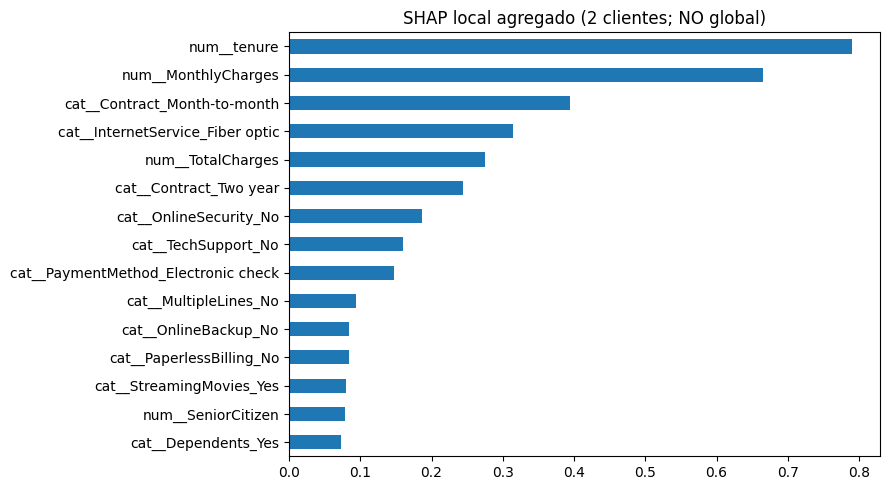

,mean_abs_SHAP (global)
cat__Contract_Month-to-month,0.418366
num__tenure,0.371627
num__MonthlyCharges,0.272235
cat__InternetService_Fiber optic,0.269896
num__TotalCharges,0.198070
cat__Contract_Two year,0.196085
cat__PaymentMethod_Electronic check,0.193784
cat__OnlineSecurity_No,0.182724
cat__TechSupport_No,0.165810
cat__PaperlessBilling_No,0.106973


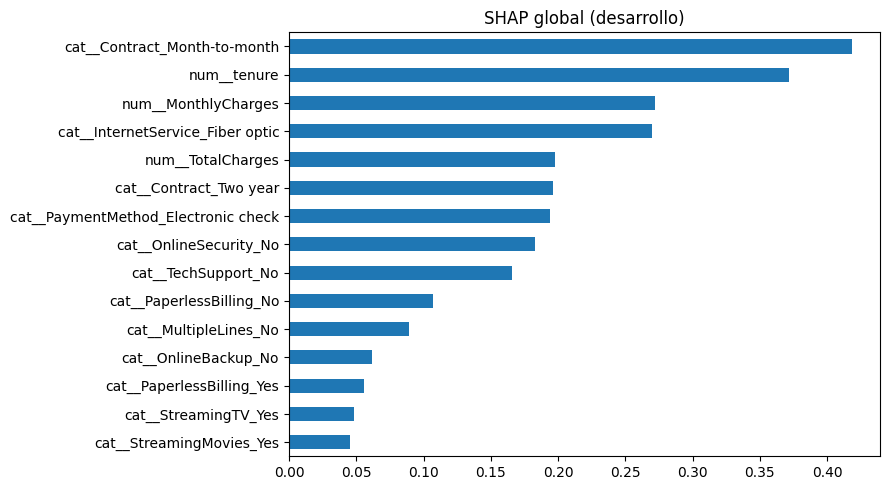

Cliente 1 | Real=0 | Probabilidad churn=0.037


,regla_lime,peso
0,num__MonthlyCharges > 0.89,0.132727
1,cat__Contract_Month-to-month <= 0.00,-0.132582
2,num__tenure > 0.55,-0.094295
3,cat__Contract_Two year > 0.00,-0.082276
4,0.50 < cat__InternetService_Fiber optic <= 1.00,0.082245
5,cat__PaymentMethod_Electronic check <= 0.00,-0.059144
6,num__TotalCharges > 0.48,-0.049787
7,cat__OnlineSecurity_No <= 0.00,-0.046705
8,cat__TechSupport_No <= 0.00,-0.034247
9,cat__MultipleLines_No <= 0.00,0.033274


Cliente 2 | Real=0 | Probabilidad churn=0.808


,regla_lime,peso
0,0.00 < cat__Contract_Month-to-month <= 1.00,0.134485
1,num__tenure <= -0.96,0.133070
2,num__MonthlyCharges > 0.89,0.127603
3,cat__Contract_Two year <= 0.00,0.088051
4,0.50 < cat__InternetService_Fiber optic <= 1.00,0.073883
5,0.00 < cat__OnlineSecurity_No <= 1.00,0.056498
6,cat__PaymentMethod_Electronic check <= 0.00,-0.050849
7,cat__TechSupport_No <= 0.00,-0.041448
8,cat__MultipleLines_No <= 0.00,0.033070
9,cat__PaperlessBilling_No <= 0.00,0.027935


,RF_impurity_importance
num__tenure,0.145973
num__TotalCharges,0.115891
cat__Contract_Month-to-month,0.106382
num__MonthlyCharges,0.077622
cat__OnlineSecurity_No,0.058430
cat__InternetService_Fiber optic,0.051130
cat__TechSupport_No,0.050381
cat__PaymentMethod_Electronic check,0.042059
cat__Contract_Two year,0.035003
cat__InternetService_DSL,0.023444


Advertencia: importancia por impureza puede ser sesgada y no es causal. SHAP y LIME pueden diferir por método y perturbaciones.


In [8]:
# PASO 14 · SHAP, LIME Y FEATURE IMPORTANCE (MISMOS 2 CLIENTES)
# XAI para cualquier pipeline: KernelExplainer sobre un subconjunto preprocesado,
# de costo controlado; SHAP TreeExplainer para árboles compatibles si funciona.
pre=final_model.named_steps['prep'];clf=final_model.named_steps['model']
Xbackground=np.asarray(pre.transform(X_dev.sample(min(80,len(X_dev)),random_state=SEED)),dtype=float)
Xexplain=np.asarray(pre.transform(X_test.iloc[:2]),dtype=float)
feat=pre.get_feature_names_out().tolist();print('Variables transformadas:',len(feat))
np.random.seed(SEED)
try:
    if selected_name in ('RandomForest','CatBoost','LightGBM','XGBoost'):
        tree_exp=shap.TreeExplainer(clf)
        sv_raw=tree_exp.shap_values(Xexplain)
        sv=np.asarray(sv_raw)
        # sklearn RF SHAP puede ser [n,p,2]; algunas versiones lista de clases
        if isinstance(sv_raw,list):sv=np.asarray(sv_raw[1])
        elif sv.ndim==3:sv=sv[:,:,1]
        shap_method='TreeExplainer'
    else:raise ValueError('Se utilizará KernelExplainer')
except Exception as ex:
    print('Usando KernelExplainer (modelo genérico):',str(ex)[:150])
    bg=shap.sample(Xbackground,min(25,len(Xbackground)),random_state=SEED)
    ke=shap.KernelExplainer(lambda a:clf.predict_proba(np.asarray(a))[:,1],bg)
    sv=np.asarray(ke.shap_values(Xexplain,nsamples=150))
    if sv.ndim==3:sv=sv[:,:,1]
    shap_method='KernelExplainer'
sv=np.asarray(sv)
if sv.ndim==1:sv=sv.reshape(1,-1)
assert sv.shape==(2,len(feat)),f'SHAP shape inesperada: {sv.shape}'
importance=pd.Series(np.abs(sv).mean(axis=0),index=feat).sort_values(ascending=False)
print('SHAP:',shap_method);display(importance.head(15).to_frame('mean_abs_SHAP (2 clientes)'))
fig,ax=plt.subplots(figsize=(9,5));importance.head(15).sort_values().plot.barh(ax=ax);ax.set_title('SHAP local agregado (2 clientes; NO global)');plt.tight_layout();plt.savefig(FIG/'shap_local.png',dpi=145);plt.show()
# Explicación GLOBAL: muestreo de desarrollo independiente del conjunto de prueba.
Xglobal=np.asarray(pre.transform(X_dev.sample(min(60,len(X_dev)),random_state=SEED+2)),dtype=float)
try:
    if shap_method=='TreeExplainer':
        sgr=tree_exp.shap_values(Xglobal);sg=np.asarray(sgr)
        if isinstance(sgr,list):sg=np.asarray(sgr[1])
        elif sg.ndim==3:sg=sg[:,:,1]
    else:sg=np.asarray(ke.shap_values(Xglobal[:20],nsamples=150))
    if sg.ndim==3:sg=sg[:,:,1]
    global_imp=pd.Series(np.abs(sg).mean(axis=0),index=feat).sort_values(ascending=False)
    display(global_imp.head(15).to_frame('mean_abs_SHAP (global)'))
    fig,ax=plt.subplots(figsize=(9,5));global_imp.head(15).sort_values().plot.barh(ax=ax);ax.set_title('SHAP global (desarrollo)');plt.tight_layout();plt.savefig(FIG/'shap_global.png',dpi=145);plt.show()
except Exception as e:print('Problema en SHAP global:',repr(e))
# LIME sobre el espacio transformado (todas las columnas ya numéricas), clases 0 y 1.
lime_explainer=LimeTabularExplainer(Xbackground,feature_names=feat,class_names=['No churn','Churn'],mode='classification',
                                   discretize_continuous=True,random_state=SEED)
for i in range(2):
    explanation=lime_explainer.explain_instance(Xexplain[i],clf.predict_proba,num_features=12,num_samples=750)
    print(f'Cliente {i+1} | Real={int(y_test.iloc[i])} | Probabilidad churn={prob[i]:.3f}')
    display(pd.DataFrame(explanation.as_list(),columns=['regla_lime','peso']))
    explanation.save_to_file(str(REPORTS/f'lime_cliente_{i+1}.html'))
# Random Forest: feature importance sobre preprocesador ajustado con dev, solo comparativo.
rf=clone(models['RandomForest']).fit(X_dev,y_dev)
rf_feat=rf.named_steps['prep'].get_feature_names_out()
rf_imp=pd.Series(rf.named_steps['model'].feature_importances_,index=rf_feat).sort_values(ascending=False)
display(rf_imp.head(15).to_frame('RF_impurity_importance'))
print('Advertencia: importancia por impureza puede ser sesgada y no es causal. SHAP y LIME pueden diferir por método y perturbaciones.')

## PASO 15 · Modelo económico demostrativo y Business Pitch

Supuestos comerciales **hipotéticos y editables**, no medidos por el dataset: el riesgo pronosticado no equivale a éxito de una campaña. Sin experimento controlado no podemos afirmar uplift causal. 

$$\operatorname{ROI}=\frac{\operatorname{Beneficio\ neto}-\operatorname{Costo}}{\operatorname{Costo}}\times100\%$$

Una estimación orientativa de retorno debe incluir **efectividad incremental** de la intervención, costo por contacto, incentivos y margen retenido. Se presentan escenarios de sensibilidad, no promesas.

In [9]:
# PASO 16 · ESCENARIOS ECONÓMICOS Y EXPORTACIÓN A STREAMLIT
# Sin utilizar el test para decidir el modelo. Para una simulación comercial usamos probabilidades OOF de desarrollo.
scenarios=[]
for intervention_effect in [.05,.10,.20]:
    for contact_cost in [2,5,10]:
        eligible=(oof>=threshold)
        n_contact=int(eligible.sum())
        # total esperado de abandonos entre contactados (solo proxy, NO efecto causal)
        expected_churn=float(oof[eligible].sum())
        margin_12m=120.0  # USD de margen a 12 meses por retención efectiva: HIPOTÉTICO
        additional_retained=expected_churn*intervention_effect
        revenue=additional_retained*margin_12m
        cost=n_contact*contact_cost+300 # 300 USD costos fijos hipotéticos
        scenarios.append({'eficacia_incremental_hipotetica':intervention_effect,'costo_contacto_USD':contact_cost,
                          'clientes_contactados':n_contact,'retenciones_adicionales_esperadas':additional_retained,
                          'beneficio_bruto_USD':revenue,'costo_total_USD':cost,
                          'beneficio_neto_USD':revenue-cost,'roi_pct':100*(revenue-cost)/cost if cost else np.nan})
business=pd.DataFrame(scenarios);display(business)
fig=px.line(business,x='costo_contacto_USD',y='beneficio_neto_USD',color='eficacia_incremental_hipotetica',markers=True,
            title='Análisis de sensibilidad: supuestos, NO resultados causales');fig.show()
# Artefactos para futuro Streamlit; se exporta el pipeline COMPLETO y metadatos.
joblib.dump(final_model,MODELS/'churn_model.joblib')
joblib.dump(rf,MODELS/'random_forest_reference.joblib')
pd.DataFrame([final_metrics]).to_csv(REPORTS/'final_metrics.csv',index=False)
bench.to_csv(REPORTS/'baseline_cv.csv',index=False);opt_table.to_csv(REPORTS/'optimizer_comparison.csv',index=False)
pareto.to_csv(REPORTS/'pareto.csv',index=False);all_nsga.to_csv(REPORTS/'nsga_all.csv',index=False)
business.to_csv(REPORTS/'business_scenarios_HYPOTHETICAL.csv',index=False)
threshold_cv.to_csv(REPORTS/'threshold_oof.csv',index=False)
metadata={'model_name':selected_name,'selection_method':selection_type,'threshold':threshold,
          'columns':list(X.columns),'numerical_features':num_cols,'categorical_features':cat_cols,
          'categorical_options':{c:sorted(X_dev[c].dropna().astype(str).unique().tolist()) for c in cat_cols},
          'numeric_defaults':{c:float(X_dev[c].median()) for c in num_cols},
          'category_defaults':{c:str(X_dev[c].mode().iloc[0]) for c in cat_cols},
          'dataset_name':CSV.name,'test_evaluated_once_in_this_run':True,'business_numbers_are_hypothetical':True}
(MODELS/'metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding='utf-8')
print('Archivos exportados a:',ART.resolve())

,eficacia_incremental_hipotetica,costo_contacto_USD,clientes_contactados,retenciones_adicionales_esperadas,beneficio_bruto_USD,costo_total_USD,beneficio_neto_USD,roi_pct
0,0.05,2,1826,53.050783,6366.093972,3952,2414.093972,61.085374
1,0.05,5,1826,53.050783,6366.093972,9430,-3063.906028,-32.491050
2,0.05,10,1826,53.050783,6366.093972,18560,-12193.906028,-65.699925
3,0.10,2,1826,106.101566,12732.187945,3952,8780.187945,222.170748
4,0.10,5,1826,106.101566,12732.187945,9430,3302.187945,35.017900
5,0.10,10,1826,106.101566,12732.187945,18560,-5827.812055,-31.399849
6,0.20,2,1826,212.203132,25464.375890,3952,21512.375890,544.341495
7,0.20,5,1826,212.203132,25464.375890,9430,16034.375890,170.035799
8,0.20,10,1826,212.203132,25464.375890,18560,6904.375890,37.200301


Archivos exportados a: /home/paul/Documents/SEMESTRE 8/PA - APRENDIZAJE AUTOMATICO /Repository/Optimización de Machine Learning, Explainable AI y Business Pitch/artifacts


## Conclusiones y preparación del Business Pitch

Al finalizar la ejecución, responder usando **las tablas generadas**, no supuestos:  
1. ¿Cuál fue el mejor modelo por ROC-AUC de validación cruzada y cuánto varió entre folds?  
2. ¿Qué optimizador encontró el mejor resultado y a qué costo computacional?  
3. ¿Qué compromiso muestra el frente de Pareto entre F1 y latencia?  
4. ¿Qué variables señala SHAP a nivel global y para los dos clientes? ¿Coincide LIME? ¿Cómo difiere la importancia por impureza de Random Forest?  
5. ¿Cómo se interpreta el umbral comercial seleccionado? ¿Qué falsos positivos y negativos aparecieron?  
6. ¿Qué riesgos limitan la venta? *drift*, calidad del dato, sesgos, calibración y ausencia de prueba causal de retención.

**Guion comercial (5 minutos):** 2 min problema → demo de producto y diferenciador; 2 min objeciones técnicas/económicas; 1 min cierre. Preparar 5 diapositivas: problema, solución, evidencia de CV/test, XAI/seguridad, escenario económico y oferta.  

**Pendiente fuera del notebook para completar toda la entrega:** desplegar Streamlit, publicar repositorio en GitHub y compartir URL funcional. El notebook genera los modelos y tablas necesarios para construir esas cuatro secciones de la aplicación.